# Удовлетворённость авиапассажиров: модель и абляции

ДЗ 2 продолжает [исследование baseline](01_satisfaction_research.ipynb). Проверим, меняется ли качество при переходе от логистической регрессии к LightGBM и помогают ли два произведения оценок услуг. Данные — конкурсный `train.csv`, метрика — ROC-AUC. Результаты относятся к синтетическим конкурсным данным и не проверяют перенос на реальных пассажиров.

## Вопросы и протокол

1. Насколько отличается качество LightGBM от baseline на тех же признаках и разбиениях?
2. Меняют ли качество произведения оценок A = Wi-Fi × онлайн-посадка и B = комфорт кресла × развлечения?

В ДЗ 1 линейная модель допускала уверенные ошибки; её ROC-AUC на личных поездках был 0,651831 против 0,919792 на деловых. LightGBM выбран для проверки более гибкой модели, способной описывать пороги и сочетания признаков. Сам по себе этот срез не объясняет ошибок и не доказывает, что их причина в линейности.

Гипотеза A: произведение оценок Wi-Fi и онлайн-посадки может помочь модели учитывать сочетание цифровых сервисов. Гипотеза B: произведение оценок кресла и развлечений может помочь учитывать сочетание услуг во время полёта. Пары выбраны с учётом прежней работы на этих данных и связанных публикаций в [протоколе](../reports/hw2/protocol.md). Деревья могут находить взаимодействия и без новых столбцов, поэтому эффект заранее не гарантирован.

E0 — логистическая регрессия из ДЗ 1; E1 — LightGBM на исходных признаках; E2 — LightGBM + A; E3 — LightGBM + B; E4 — LightGBM + A + B. Для каждого варианта используются одни и те же пять стратифицированных фолдов, seed 42 и одни и те же преобразования исходных признаков. Медиана, стандартизация, мода и one-hot обучаются только на обучающей части каждого фолда. Произведения считаются построчно без целевой переменной. Нули сохранены как числа: их смысл неизвестен.

Сравнение E1−E0 меняет семейство модели целиком. E4−E3 измеряет добавление A при наличии B, E4−E2 — добавление B при наличии A. E4−E1 показывает совместное изменение. Эти эффекты не обязаны складываться. Параметры и гипотезы описаны в [протоколе](../reports/hw2/protocol.md); ранние исследования этих данных могли повлиять на выбор вариантов.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
if not (root / "configs/hw2.yaml").exists():
    root = root.parent
assert (root / "configs/hw2.yaml").exists(), "Запустите ноутбук из корня проекта или каталога notebooks"
report = root / "reports/hw2"
summary = pd.read_csv(report / "summary.csv")
folds = pd.read_csv(report / "folds.csv")
comparisons = pd.read_csv(report / "comparisons.csv")
slices = pd.read_csv(report / "slices.csv")

## Воспроизведение

Ноутбук показывает зафиксированный снимок полного запуска в `reports/hw2/`; численные выводы относятся к нему. Для нового запуска выполните из корня `./scripts/run_hw2.sh`, затем `python -m src.verify_hw2`, `python -m src.compare_hw2` и `python scripts/build_hw2_report.py`. Проверка сначала сверяет внутреннюю согласованность результатов, затем сравнивает фолдовые метрики с опубликованными. Отчёт нового запуска сохраняется в `outputs/hw2/report/` и не меняет опубликованный снимок. Для повторного запуска выберите пустой выходной каталог; подробности — в [README](../README.md).

## Качество моделей

Основной показатель — средний ROC-AUC пяти фолдов. В таблице также приведены стандартное отклонение по фолдам, общий OOF ROC-AUC, средний average precision (AP, сводная метрика precision–recall) и суммарное время обучения на пяти фолдах. Общий OOF ROC-AUC может отличаться от среднего из-за сравнений скоров между фолдами. Время включает обучение предобработки и модели; оно зависит от машины.

In [2]:
table = summary[["experiment", "model", "features", "mean_fold_auc", "std_fold_auc", "pooled_oof_auc", "mean_fold_ap", "fit_seconds_total"]].copy()
table = table.rename(columns={"experiment": "Опыт", "model": "Модель", "features": "Признаки", "mean_fold_auc": "ROC-AUC: среднее", "std_fold_auc": "ROC-AUC: SD", "pooled_oof_auc": "ROC-AUC: общий OOF", "mean_fold_ap": "AP: среднее", "fit_seconds_total": "Обучение, с"})
table["Модель"] = table["Модель"].replace({"logistic": "Логистическая регрессия", "lightgbm": "LightGBM"})
display(table.round(6).set_index("Опыт"))

,Модель,Признаки,ROC-AUC: среднее,ROC-AUC: SD,ROC-AUC: общий OOF,AP: среднее,"Обучение, с"
Опыт,,,,,,,
E0,Логистическая регрессия,нет,0.921555,0.000436,0.921556,0.908974,12.015
E1,LightGBM,нет,0.958039,0.000668,0.958028,0.941970,82.376
E2,LightGBM,A,0.958028,0.000679,0.958015,0.941953,85.860
E3,LightGBM,B,0.958076,0.000626,0.958063,0.941925,87.942
E4,LightGBM,A+B,0.958059,0.000643,0.958049,0.941876,88.018


LightGBM на исходных признаках достигает среднего ROC-AUC **0,958039** против **0,921555** у логистической регрессии. Разница положительна на всех пяти фолдах; смена модели одновременно меняет несколько свойств, поэтому результат нельзя приписать отдельно нелинейности. В этой серии максимальное среднее у E3 — **0,958076**; это выбор по тем же данным, на которых оценивались варианты, а не независимое подтверждение преимущества.

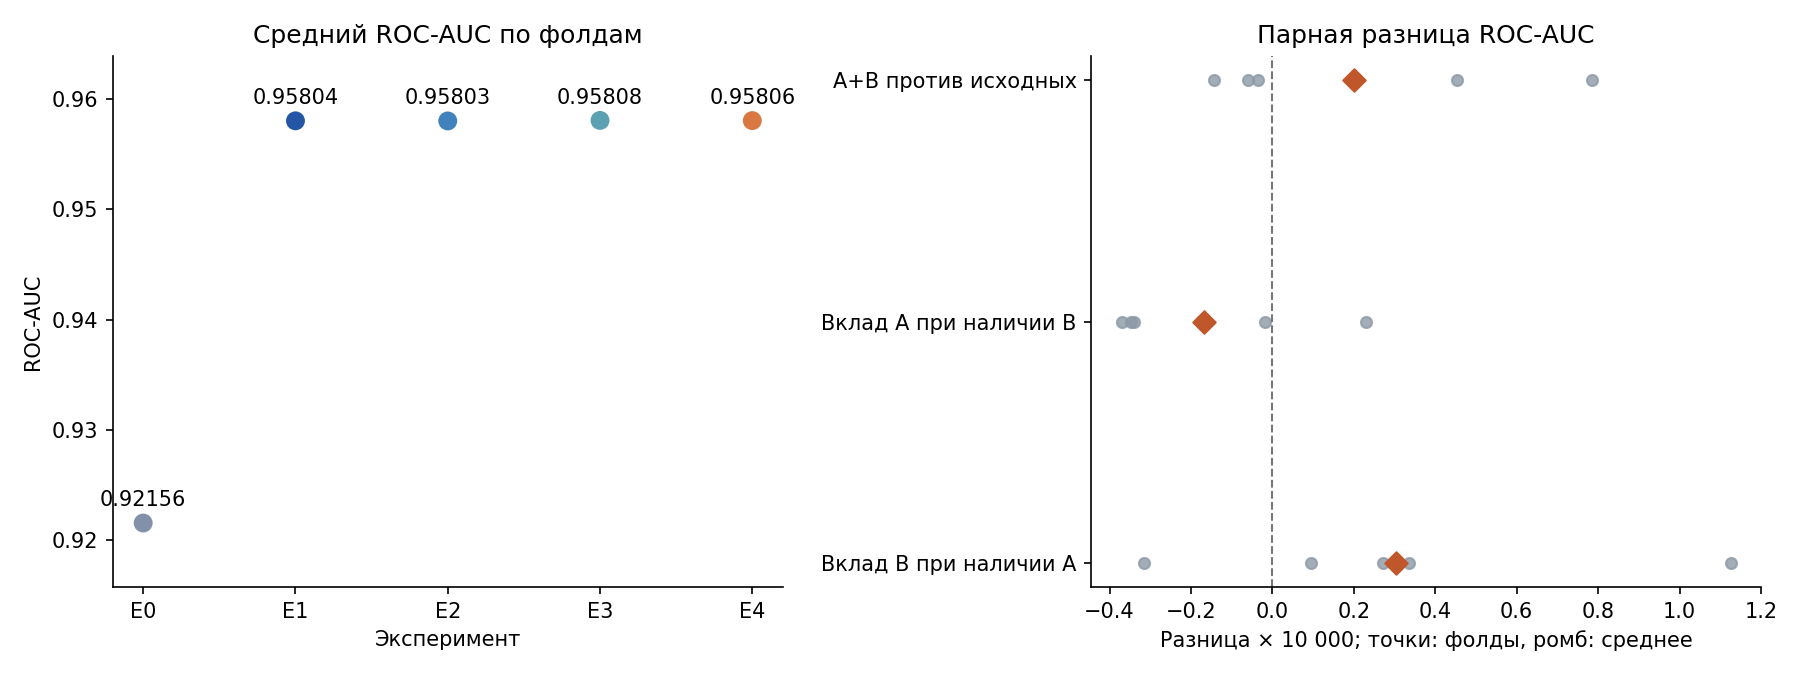

In [3]:
display(Image(filename=str(report / "comparison.png")))

На правом графике каждая точка — парная разница на одном фолде, ромб — среднее пяти разниц. Значения умножены на 10 000 для читаемости. Разброс между фолдами описательный: обучающие части пересекаются, поэтому точки нельзя считать пятью независимыми наборами данных.

## Абляции

В обоих сравнениях от полной конфигурации E4 убран ровно один признак. Разница считается как ROC-AUC первого варианта минус ROC-AUC второго на тех же строках. Положительная разница означает преимущество первого варианта. Среднее и значения по фолдам умножены на 10 000; стандартное отклонение описывает разброс пяти разниц, а не доверительный интервал.

In [4]:
labels = {"model": "Модель: E1 − E0", "both_features": "A и B: E4 − E1", "ablate_A": "A при B: E4 − E3", "ablate_B": "B при A: E4 − E2"}
columns = ["mean_auc_delta", "std_auc_delta", "positive_folds"]
comparison_table = comparisons.set_index("comparison")[columns].copy()
comparison_table[["mean_auc_delta", "std_auc_delta"]] *= 10_000
comparison_table = comparison_table.rename(index=labels, columns={"mean_auc_delta": "Средняя разница × 10 000", "std_auc_delta": "SD × 10 000", "positive_folds": "Фолдов с разницей > 0"})
comparison_table.index.name = "Сравнение"
display(comparison_table.round(3))
fold_columns = [f"fold_{i}_delta" for i in range(1, 6)]
fold_deltas = comparisons.set_index("comparison")[fold_columns].rename(index=labels).T * 10_000
fold_deltas.index = [f"Фолд {i}" for i in range(1, 6)]
fold_deltas.index.name = "Разница × 10 000"
fold_deltas.columns.name = "Сравнение"
display(fold_deltas.round(3))

,Средняя разница × 10 000,SD × 10 000,Фолдов с разницей > 0
Сравнение,,,
Модель: E1 − E0,364.834,8.269,5
A и B: E4 − E1,0.200,0.360,2
A при B: E4 − E3,-0.169,0.238,1
B при A: E4 − E2,0.302,0.470,4


Сравнение,Модель: E1 − E0,A и B: E4 − E1,A при B: E4 − E3,B при A: E4 − E2
Разница × 10 000,,,,
Фолд 1,355.933,-0.037,-0.370,0.335
Фолд 2,353.831,0.785,-0.347,1.126
Фолд 3,373.573,-0.060,0.229,0.272
Фолд 4,369.211,-0.143,-0.340,-0.317
Фолд 5,371.621,0.454,-0.017,0.095


Совместное добавление A и B к E1 даёт в среднем **+0,000020**, но разница положительна только в двух фолдах из пяти. Добавление A к модели с B даёт **−0,000017** в среднем и положительную разницу в одном фолде; добавление B к модели с A — **+0,000030**, положительную в четырёх. Эффекты малы по сравнению с заменой модели, а знак меняется между фолдами. Эти данные не позволяют уверенно утверждать, что взаимодействия устойчиво улучшают качество. Отрицательные результаты сохранены наряду с положительными. Возможное объяснение малого эффекта: деревья уже могут строить сочетания исходных оценок, а произведение сводит разные пары значений к одному числу. Эта серия не позволяет установить, почему получилось именно так.

## Срез по типу поездки

Сравним объединённый OOF ROC-AUC исходной логистической модели и двух LightGBM. На графике указаны размеры групп и доли положительных ответов. Точки показывают метрики, а не интервалы неопределённости. Срез описательный; он не доказывает причину ошибок и не является отдельной проверочной выборкой.

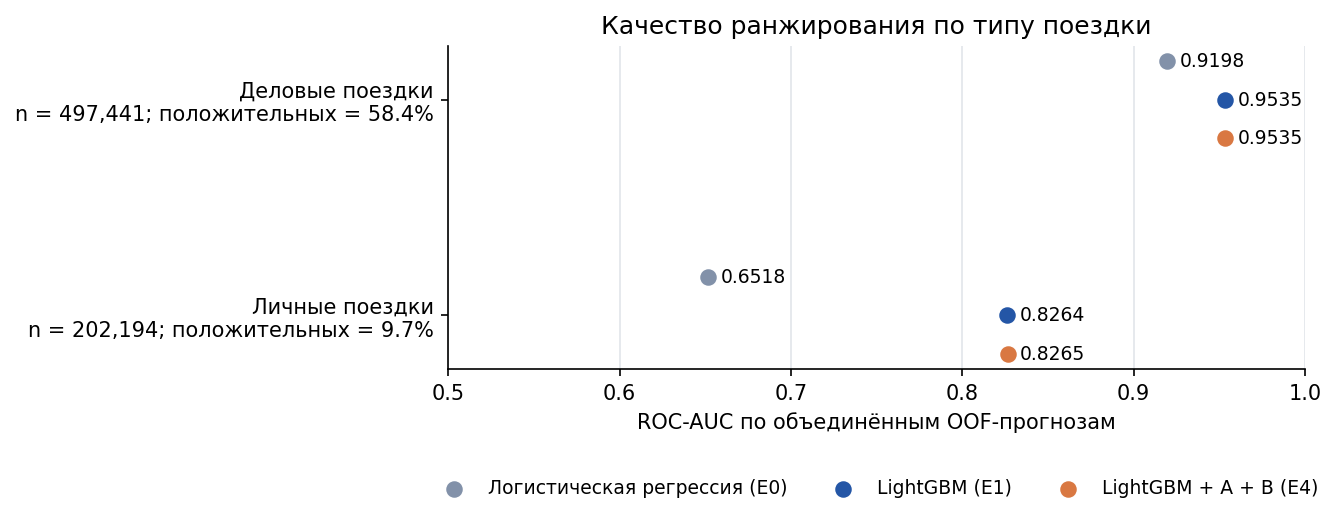

In [5]:
display(Image(filename=str(report / "travel_slices.png")))

На личных поездках ROC-AUC вырастает с **0,651831** у E0 до **0,826383** у E1, но остаётся ниже, чем на деловых поездках (**0,953475** у E1). У E4 этот разрыв тоже сохраняется. Эти значения не показывают качество при конкретном пороге или полезность для авиакомпании; калибровка и перенос не проверялись.

## Ограничения и выводы

На выбранных фолдах переход к LightGBM улучшил ранжирование относительно baseline. Два заданных взаимодействия дали малые и неоднородные изменения; на основании этой серии их практическая польза не установлена. Предыдущая работа с конкурсом использовала те же данные, поэтому исследование не является независимым подтверждением. Доверительный интервал из ДЗ 1 относится только к объединённому OOF ROC-AUC baseline при фиксированных прогнозах; он не является интервалом разницы моделей. Модели в bootstrap повторно не обучались, поэтому интервал не учитывает разброс обучения.

Для продолжения можно повторить фиксированные сравнения на других разбиениях и проверить срезы, не считая эти разбиения независимыми датасетами; отдельный интерес представляет исключение оценок услуг, если нужен сценарий без них. Реальный перенос требует новых данных и уточнения времени доступности признаков.